In [1]:
import openseespy.opensees as ops
import opsvis as opsv
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# unit conversion
m=1
mm=0.001*m
kn=1
pa=1
kpa=1000*pa
mpa=1000*kpa
gpa=1000*mpa

In [3]:
ops.wipe()
ops.model('basic', '-ndm', 2, '-ndf', 3)

In [4]:
# define steel material
mattag=1
fy=350*mpa
E=200*gpa
b=0.001
ops.uniaxialMaterial('Steel02', mattag, fy, E, b)

In [5]:
# define concrete material
fpc=-30*mpa
epsc0=-0.002
fpcu=-20*mpa
epsu=-0.008
lamda=0.1
ft=3*mpa
ets=150*mpa
ops.uniaxialMaterial('Concrete02', 2, fpc, epsc0, fpcu, epsu, lamda, ft, ets)
ops.uniaxialMaterial('Concrete02',3,
                     -25*mpa,
                     -0.002,
                     -15*mpa,
                     -0.006,
                     0.1,
                     2*mpa,
                     100*mpa)

ops.node(1, 0.0,0.0)
ops.node(2, 0.0,1)
ops.node(3, 0.0,2)
ops.node(4, 0.0,3)
ops.fix(1, 1, 1, 1)

In [6]:
# def getsection():
#section defination
# Bd=400*mm
# D=600*mm
confinedconcretetag=2
unconfinedconcretetag=3
numsubdiv=10
sectag=1
ops.section('Fiber', sectag, '-GJ', 1.0e6)
ops.patch('rect',confinedconcretetag,numsubdiv,1,-450*mm/2,-300*mm/2,450*mm/2,300*mm/2) #CONFINED CONCRETE

ops.patch('quad',unconfinedconcretetag,1,1,450*mm/2,400*mm/2,450*mm/2,-400*mm/2,600*mm/2,-400*mm/2,600*mm/2,400*mm/2) #unconfined concrete
ops.patch('quad',unconfinedconcretetag,1,1,-450*mm/2,400*mm/2,-450*mm/2,300*mm/2,450*mm/2,300*mm/2,450*mm/2,400*mm/2) #unconfined concrete
ops.patch('quad',unconfinedconcretetag,1,1,-600*mm/2,400*mm/2,-600*mm/2,-400*mm/2,-450*mm/2,-400*mm/2,-450*mm/2,400*mm/2) #unconfined concrete
ops.patch('quad',unconfinedconcretetag,1,1,-450*mm/2,-300*mm/2,-450*mm/2,-400*mm/2,450*mm/2,-400*mm/2,450*mm/2,-300*mm/2) #unconfined concrete
ops.layer('straight', mattag, 3,300*mm**2,450*mm/2,300*mm/2,450*mm/2,-300*mm/2) #steel layer
ops.layer('straight', mattag, 3,300*mm**2,-450*mm/2,300*mm/2,-450*mm/2,-300*mm/2) #steel layer

In [7]:
#geometry transformation
ops.geomTransf('PDelta', 1)
ops.beamIntegration('Lobatto', 1, sectag, 3)
mass=6000

ops.element('forceBeamColumn', 1, 1, 2, 1, 1,'-mass',mass) #ops.element('forceBeamColumn', eleTag, iNode, jNode, transfTag, integrationTag, '-mass', massDensity)
ops.element('forceBeamColumn', 2, 2, 3, 1, 1,'-mass',mass)
ops.element('forceBeamColumn', 3, 3, 4, 1, 1,'-mass',mass)

In [8]:
# def plot():
fib_sec_1 = [
    ['section', 'Fiber', 1, '-GJ', 1.0e6],
    ['patch','rect',confinedconcretetag,numsubdiv,1,-450*mm/2,-300*mm/2,450*mm/2,300*mm/2],
    ['patch','quad',unconfinedconcretetag,1,2,450*mm/2,400*mm/2,450*mm/2,-400*mm/2,600*mm/2,-400*mm/2,600*mm/2,400*mm/2],   # right cover (यो थपियो)
    ['patch','quad',unconfinedconcretetag,1,5,-450*mm/2,400*mm/2,-450*mm/2,300*mm/2,450*mm/2,300*mm/2,450*mm/2,400*mm/2],  # top cover
    ['patch','quad',unconfinedconcretetag,1,2,-600*mm/2,400*mm/2,-600*mm/2,-400*mm/2,-450*mm/2,-400*mm/2,-450*mm/2,400*mm/2], # left cover
    ['patch','quad',unconfinedconcretetag,1,5,-450*mm/2,-300*mm/2,-450*mm/2,-400*mm/2,450*mm/2,-400*mm/2,450*mm/2,-300*mm/2], # bottom cover
    ['layer', 'straight', mattag, 3, 300*mm**2, 450*mm/2,300*mm/2,450*mm/2,-300*mm/2],
    ['layer', 'straight', mattag, 3, 300*mm**2, -450*mm/2,300*mm/2,-450*mm/2,-300*mm/2]
]

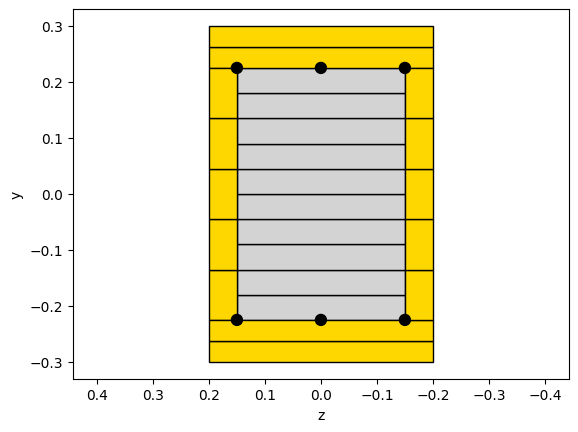

In [9]:
matcolor = ['r', 'lightgrey', 'gold', 'w', 'w', 'w']
opsv.plot_fiber_section(fib_sec_1, matcolor=matcolor)
plt.axis('equal')
plt.show()


In [10]:
#Load analysis 
px=1*kn
Vx=1*kn
delx=0.0001*m

In [11]:
def gravity():
    controlNode = 4
    controlNodeDof = 2
    linearSeriesTag = 1
    #time series
    ops.timeSeries('Linear',linearSeriesTag)

    #load pattern
    ops.pattern('Plain',1, linearSeriesTag)
    #now instead of using load at control node, we use sp command single point constraint
    ops.load(controlNode, *[0, -1*kn, 0.0])
    #xxx ops.sp(controlNode, controlNodeDof, DEL_x)xxxx

    #analysis commands
    ops.constraints("Transformation")
    ops.numberer("Plain")
    ops.system("BandGeneral")
    ops.algorithm("Newton")
    #integrator('DisplacementControl', nodeTag, dof, incr, numIter=1, dUmin=incr, dUmax=incr)
    ops.integrator('LoadControl',0.1)
    #ops.test('NormDispIncr', tol, iter, pFlag=0, nType=2)
    ops.test('NormDispIncr', 1.0e-6, 50)
    ops.analysis("Static")

    #recorder('Node', '-file', filename, , '-timeSeries', tsTag, '-time','-closeOnWrite', '-node', *nodeTags=[],'-dof', *dofs=[], respType)
    # ops.recorder('Node', '-file', "displacements.txt",'-closeOnWrite', '-time', '-node', *[4], '-dof', *[1,2,3], 'disp')
    # ops.recorder('Node', '-file', "reactions.txt", '-closeOnWrite', '-time', '-node', *[1], '-dof', *[1,2,3], 'reaction')
    
    #analyze(numIncr=1, dt=0.0, dtMin=0.0, dtMax=0.0, Jd=0)
    ops.record()
    ops.analyze(10)
    # return status

In [12]:
gravity()

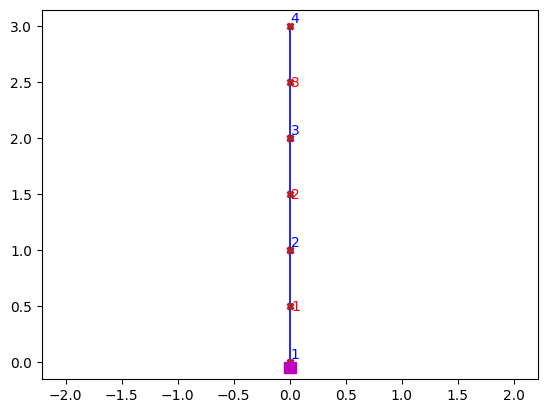

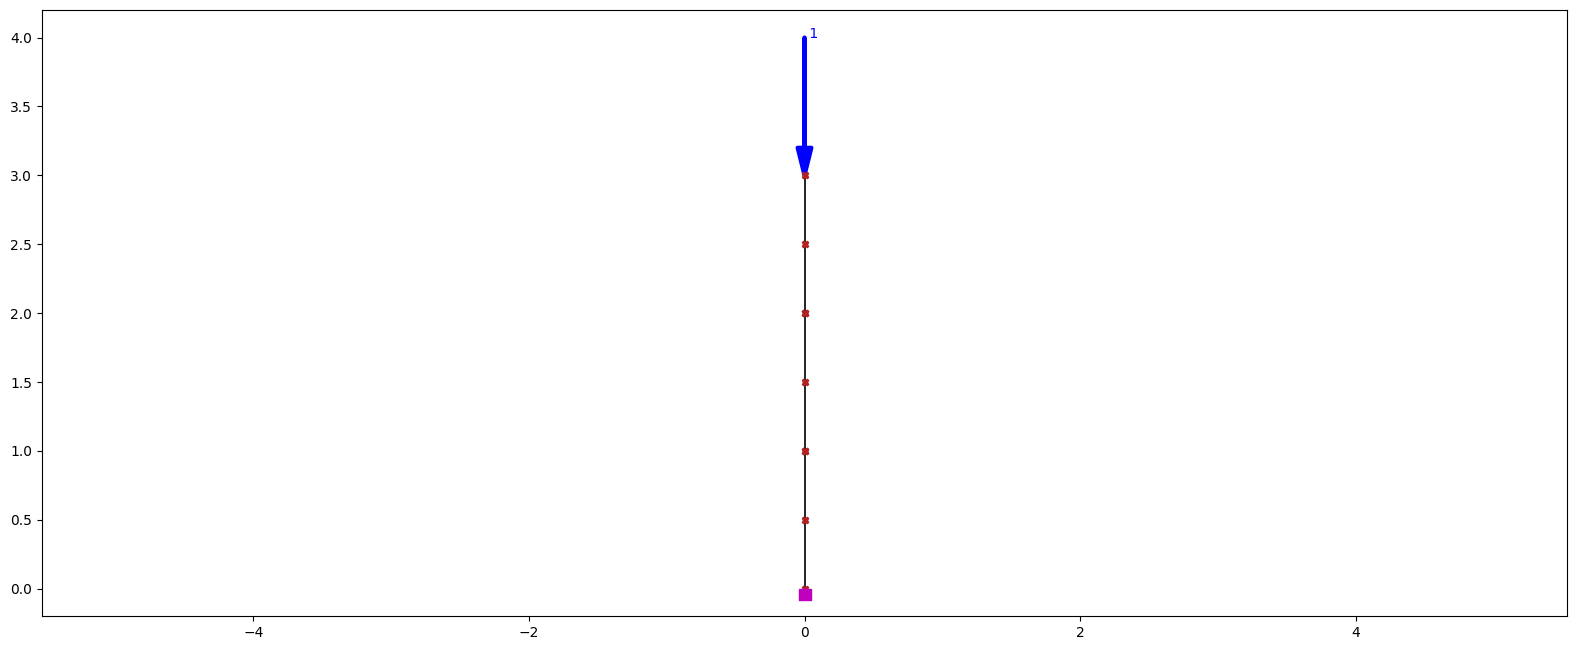

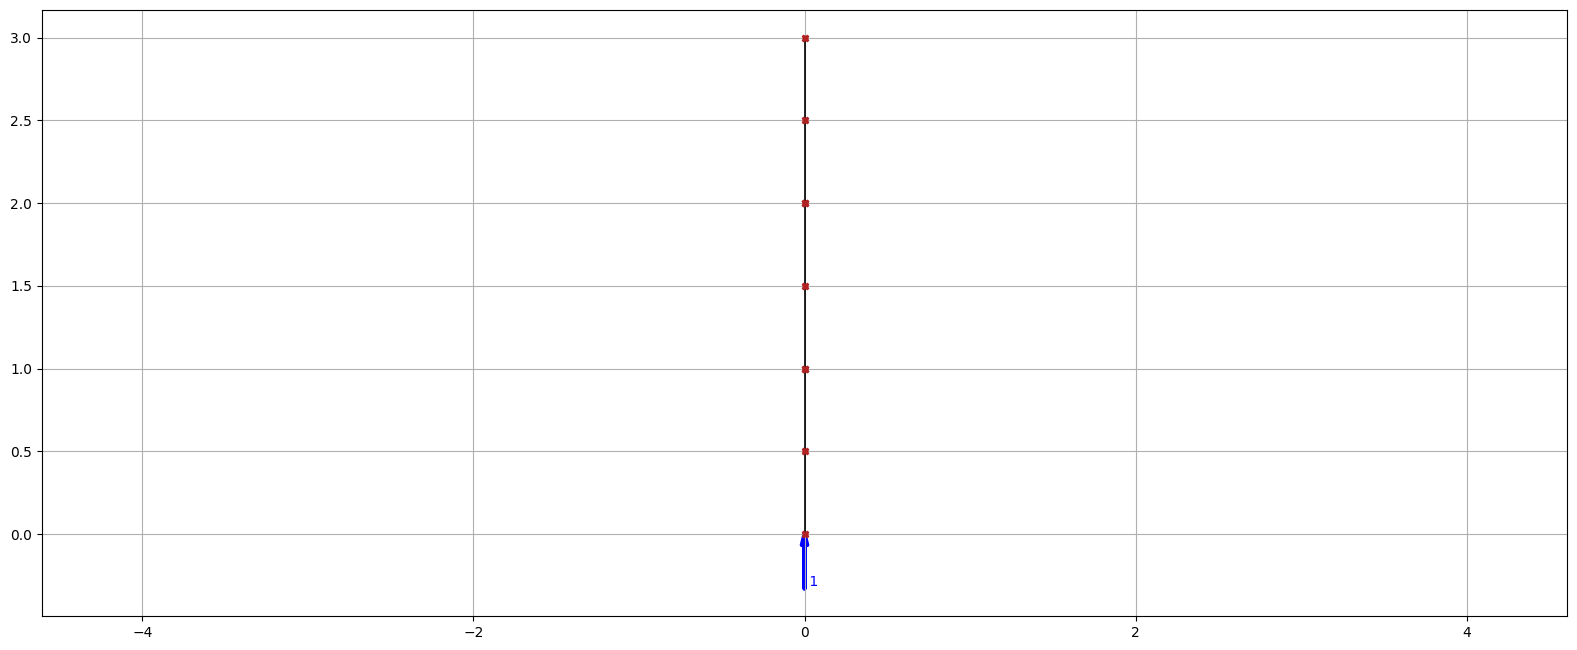

In [13]:
opsv.plot_model()
opsv.plot_load(sfac=1,fig_wi_he=(50,20))
opsv.plot_reactions(fig_wi_he=(50,20))
plt.grid()
plt.show()

Eigenvalues: [4358.700501235901, 138887.59718547508, 314170.4069390322]
   Time Periods  Frequencies
0       0.09517    10.507482
1       0.01686    59.313269
2       0.01121    89.207788


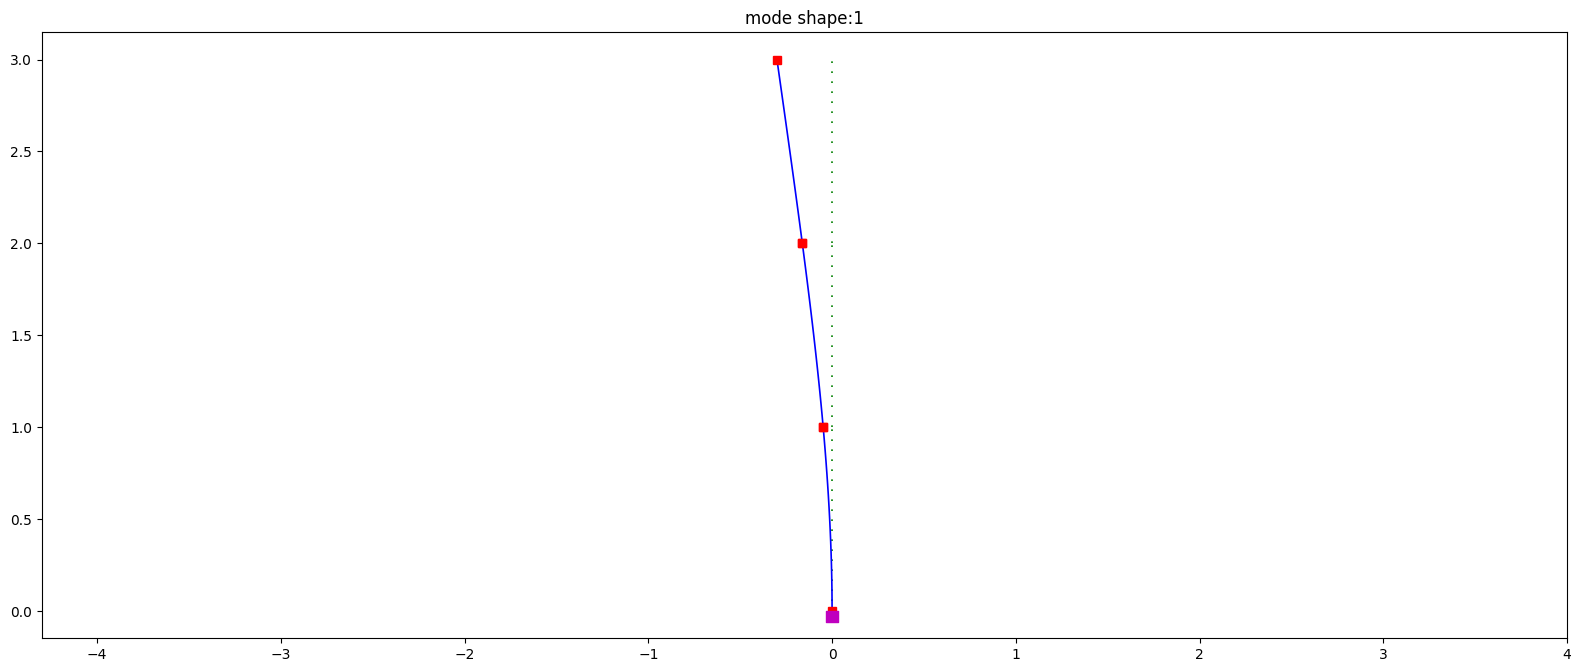

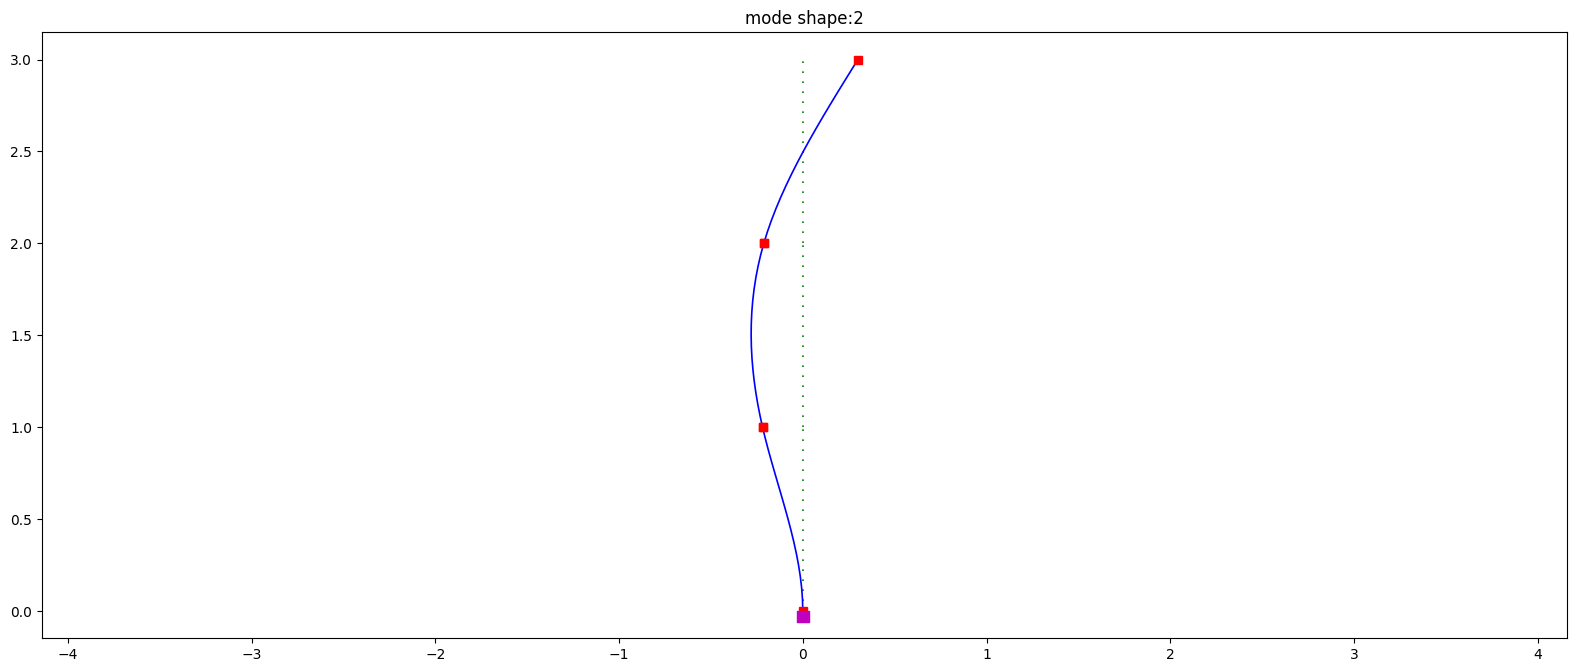

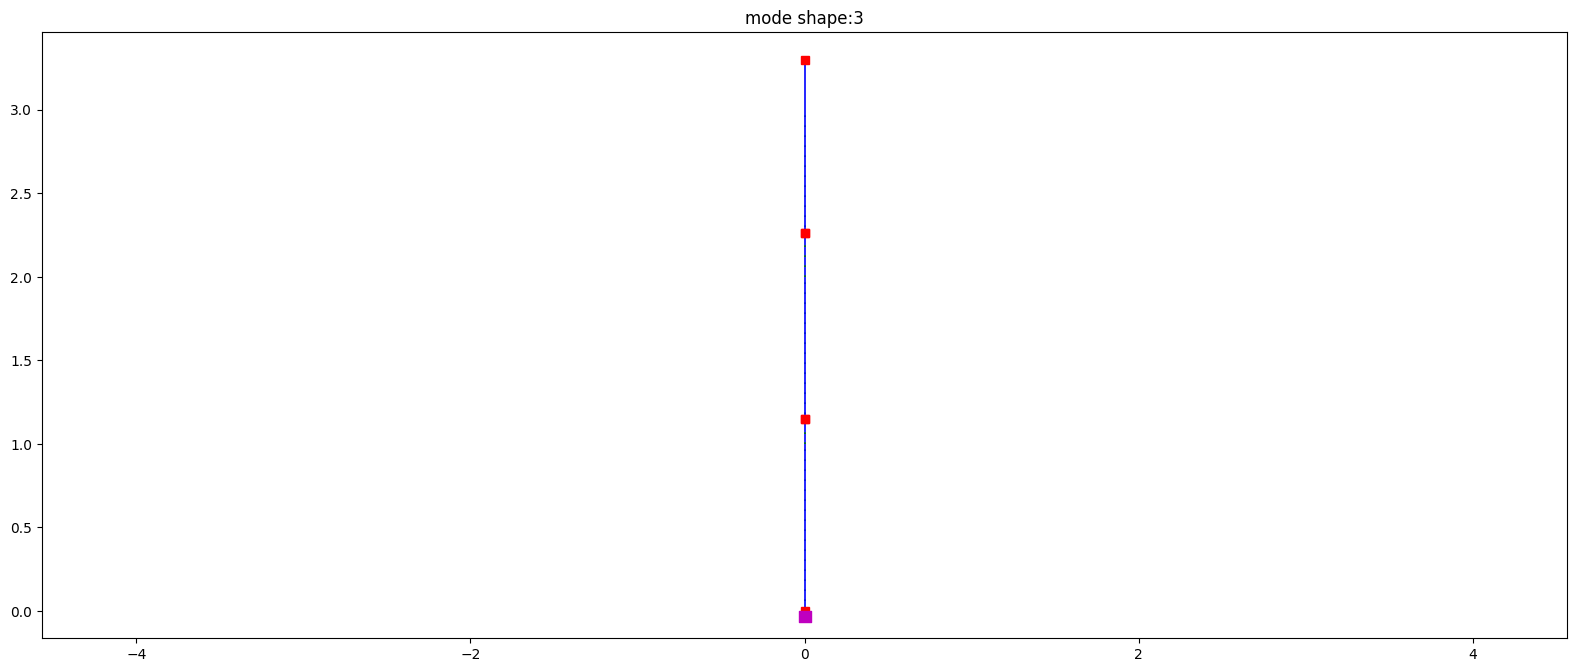

In [14]:
value=ops.eigen(3)
print("Eigenvalues:", value)
timeperiods=[]
frequency=[]
for i in range(3):
    omega=math.sqrt(value[i])
    timeperi=2*math.pi/omega
    frequencies=1/timeperi
    timeperiods.append(timeperi)
    frequency.append(frequencies)

    opsv.plot_mode_shape(i+1,fig_wi_he=(50,20))
    plt.title('mode shape:'+str(i+1))
data=pd.DataFrame({'Time Periods': timeperiods, 'Frequencies': frequency})
print(data)

In [15]:
ops.loadConst('-time', 0.0)

In [16]:
omega1=math.sqrt(value[0])
omega2=math.sqrt(value[1])

In [17]:
zeta = 0.05

alphaM = 2*zeta*omega1*omega2/(omega1 + omega2)

betaKcomm = 2*zeta/(omega1 + omega2)

print("alphaM =", alphaM)
print("betaKcomm =", betaKcomm)

alphaM = 5.608488848580746
betaKcomm = 0.00022794790980173524


In [18]:
def nltha():
    ops.rayleigh(alphaM, 0.0, 0.0, betaKcomm)
    ops.timeSeries('Path', 2, '-dt', 0.01, '-filePath', 'ground_motion.txt', '-factor', 1.0)

In [19]:
ops.rayleigh(alphaM, 0.0, 0.0, betaKcomm)

In [20]:
# Read Excel
data = pd.read_excel("elcentrogroundmotion.xlsx")

time = data.iloc[:, 0].to_numpy()
accel = data.iloc[:, 1].to_numpy()



In [21]:
time

array([0.000e+00, 2.000e-02, 4.000e-02, ..., 3.130e+01, 3.132e+01,
       3.134e+01], shape=(1568,))

In [22]:
# Calculate time step
dt = time[1] - time[0]

# If acceleration is in g:
accel = accel * 9.810       # m/s²

# Define earthquake time series
eqTS = 2
ops.wipeAnalysis()
ops.timeSeries('Path', eqTS, '-dt', dt, '-values', *accel)
# Apply earthquake in X direction
ops.pattern('UniformExcitation', 8, 1, '-accel', eqTS)

ops.constraints("Transformation")
ops.numberer("Plain")
ops.system("BandGeneral")
ops.algorithm("Newton")
ops.integrator("Newmark", 0.5, 0.25)
ops.test("NormDispIncr", 1.0e-6, 50, 0)
ops.analysis("Transient")
ops.recorder('Node', '-file', "displacements.txt",'-closeOnWrite', '-time', '-node', *[4], '-dof', 1, 'disp')
ops.recorder('Node', '-file', "reactions.txt", '-closeOnWrite', '-time', '-node', *[1], '-dof', 2, 'reaction')
ops.record()
ops.analyze(len(time)-1, dt)

WARNING - ForceBeamColumn2d::update - failed to get compatible element forces & deformations for element: 1(dW: << nan)
WARNING - ForceBeamColumn2d::update - failed to get compatible element forces & deformations for element: 2(dW: << nan)
WARNING - ForceBeamColumn2d::update - failed to get compatible element forces & deformations for element: 3(dW: << nan)
Domain::update - domain failed in update
Newmark::update() - failed to update the domain
WARNING NewtonRaphson::solveCurrentStep() -the Integrator failed in update()
DirectIntegrationAnalysis::analyze() - the Algorithm failed at time 31.18
OpenSees > analyze failed, returned: -3 error flag


-3

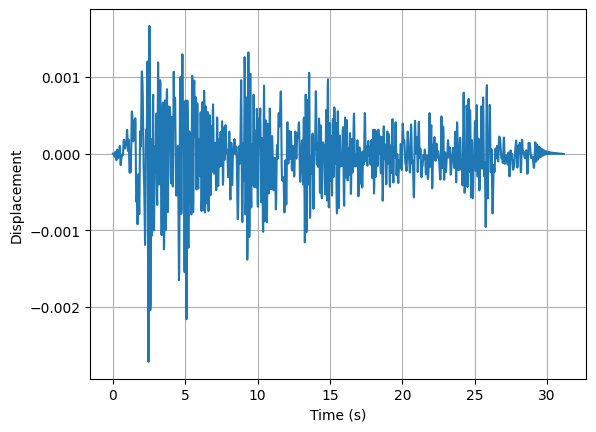

In [23]:
result = np.loadtxt('displacements.txt')

time = result[:, 0]
disp = result[:, 1]

plt.plot(time, disp)
plt.xlabel('Time (s)')
plt.ylabel('Displacement')
plt.grid()
plt.show()

In [24]:
disp


array([ 6.21764e-27, -3.35647e-06, -1.04815e-05, ..., -1.93053e-06,
       -1.62781e-06, -2.95579e-06], shape=(1559,))

In [25]:
# --- Load data ---
displacements = np.loadtxt('displacements.txt', delimiter=" ")
reactions = np.loadtxt('reactions.txt', delimiter=" ")
time = displacements[:, 0]
disp = displacements[:, 1]
# for Reactions
reactions = np.loadtxt('reactions.txt', delimiter=" ")
time = reactions[:, 0]
reaction=reactions[:, 1]


# --- CSV file 
df = pd.DataFrame({
    'time': time,
    'displacement': disp
})
dff=pd.DataFrame({
    'time': time,
    'reaction': reaction
})

df.to_csv('time_history_displacements.csv', index=False)
dff.to_csv('time_history_reactions.csv', index=False)
print("Saved: time_history_displacements.csv")
print("Saved: time_history_reactions.csv")



Saved: time_history_displacements.csv
Saved: time_history_reactions.csv


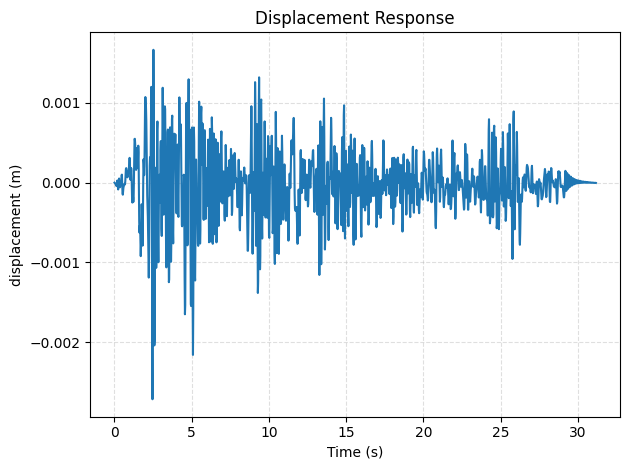

In [26]:
# --- Plot ---
fig, ax = plt.subplots()
ax.plot(time, disp)
ax.set_xlabel('Time (s)')
ax.set_ylabel('displacement (m)')
ax.set_title('Displacement Response')
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


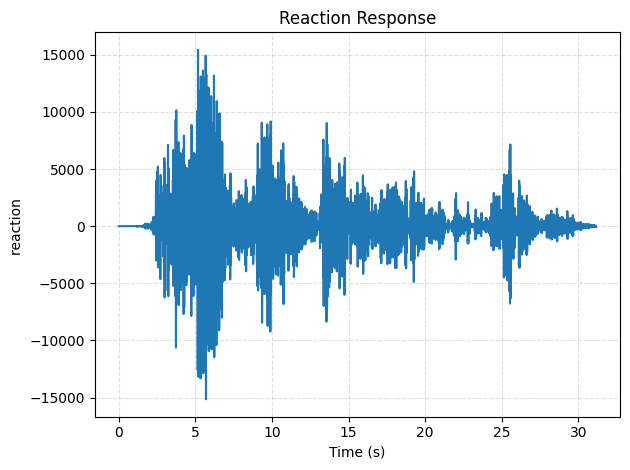

In [27]:
# --- Plot ---
fig, ax = plt.subplots()
ax.plot(time, reaction)
ax.set_xlabel('Time (s)')
ax.set_ylabel('reaction ')
ax.set_title('Reaction Response')
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()